--- Fit Results for Relaxation Analysis: 1.5% Copper Sulphate ---
Calculated T1: 28.96 ± 0.20 ms
Fitted plateau (a): 8.87 ± 0.05 V
Fitted amplitude (k): 17.92 ± 0.03 V



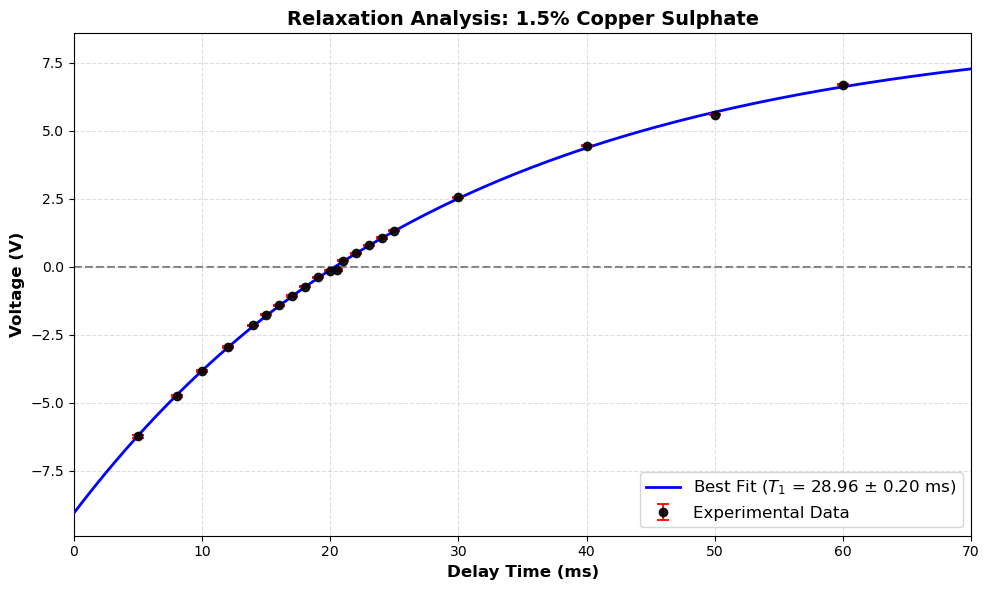

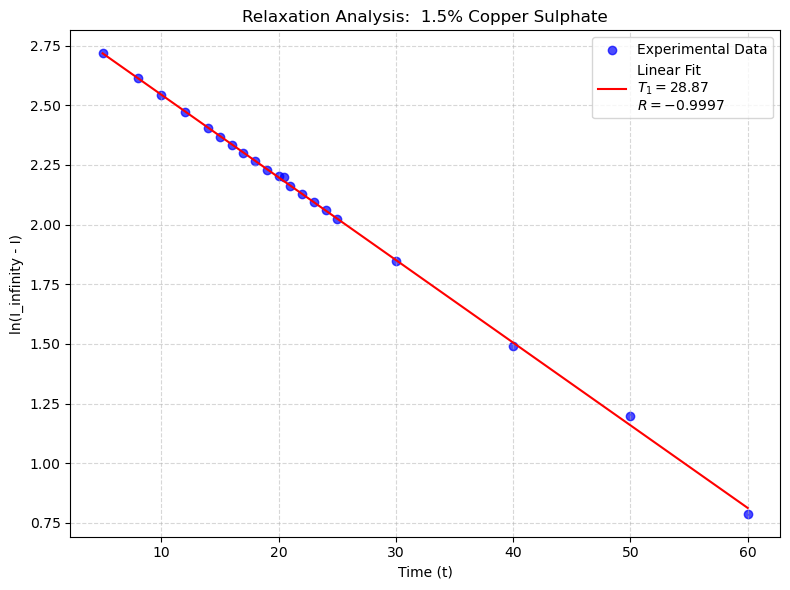

--- Fit Results for Relaxation Analysis: 3.1% Copper Sulphate ---
Calculated T1: 20.98 ± 0.76 ms
Fitted plateau (a): 10.91 ± 0.35 V
Fitted amplitude (k): 17.08 ± 0.29 V



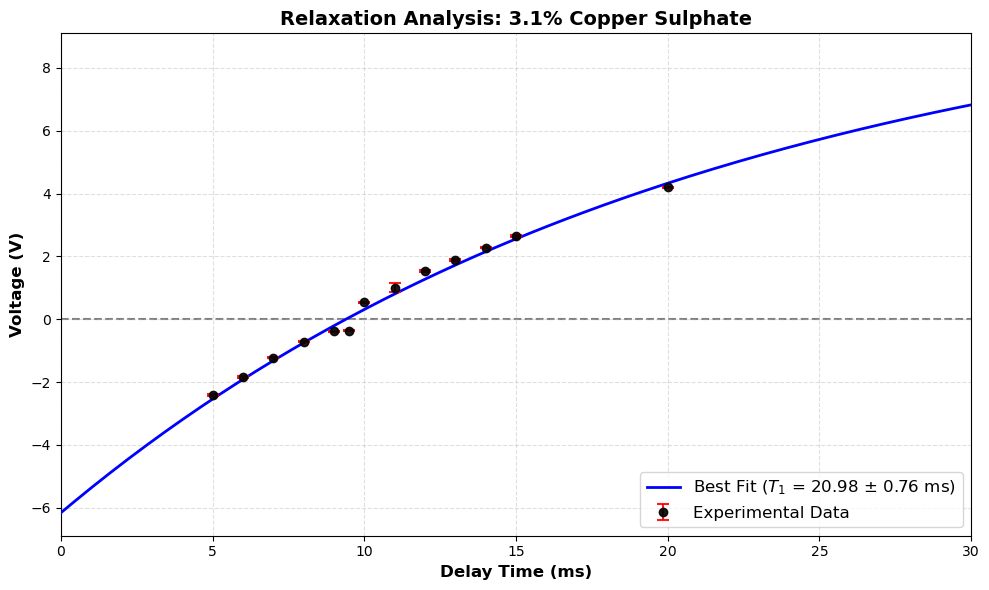

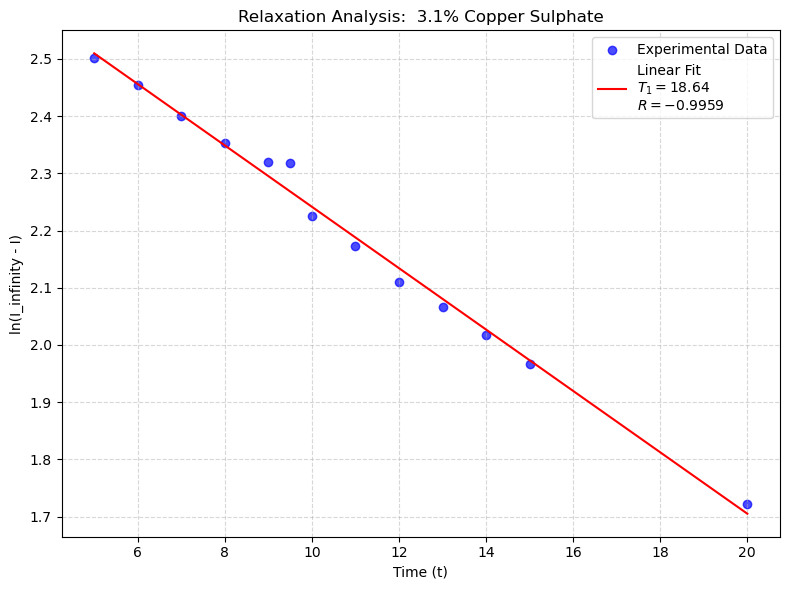

--- Fit Results for Relaxation Analysis: 6.25% Copper Sulphate ---
Calculated T1: 9.52 ± 0.09 ms
Fitted plateau (a): 6.56 ± 0.04 V
Fitted amplitude (k): 11.87 ± 0.03 V



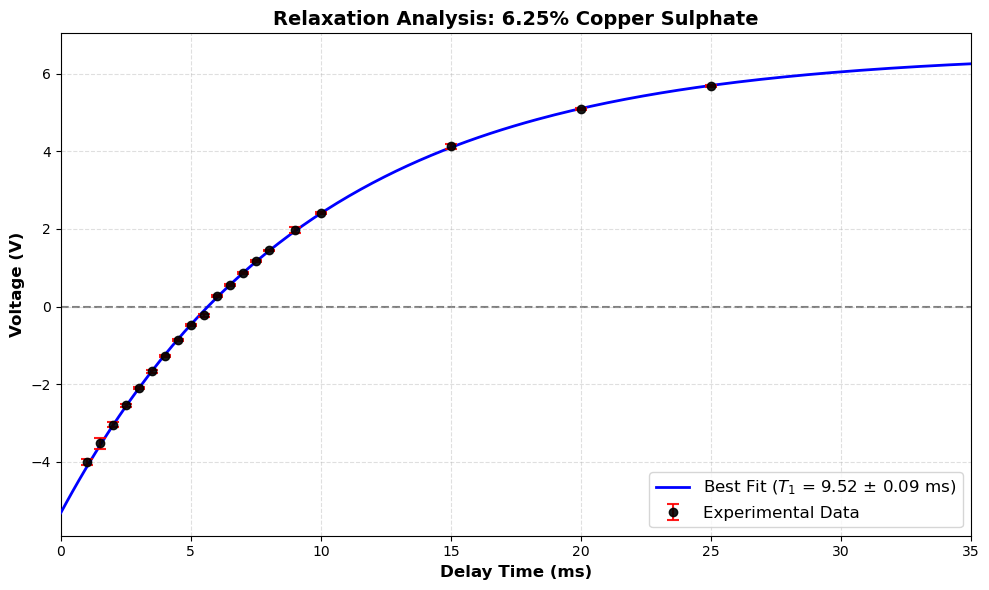

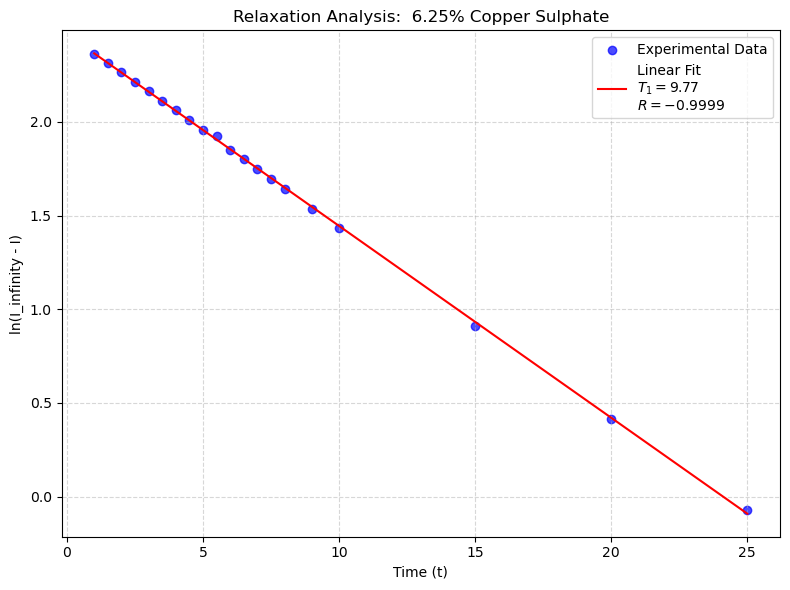

--- Fit Results for Relaxation Analysis: 12.5% Copper Sulphate ---
Calculated T1: 4.50 ± 0.07 ms
Fitted plateau (a): 10.28 ± 0.14 V
Fitted amplitude (k): 20.19 ± 0.09 V



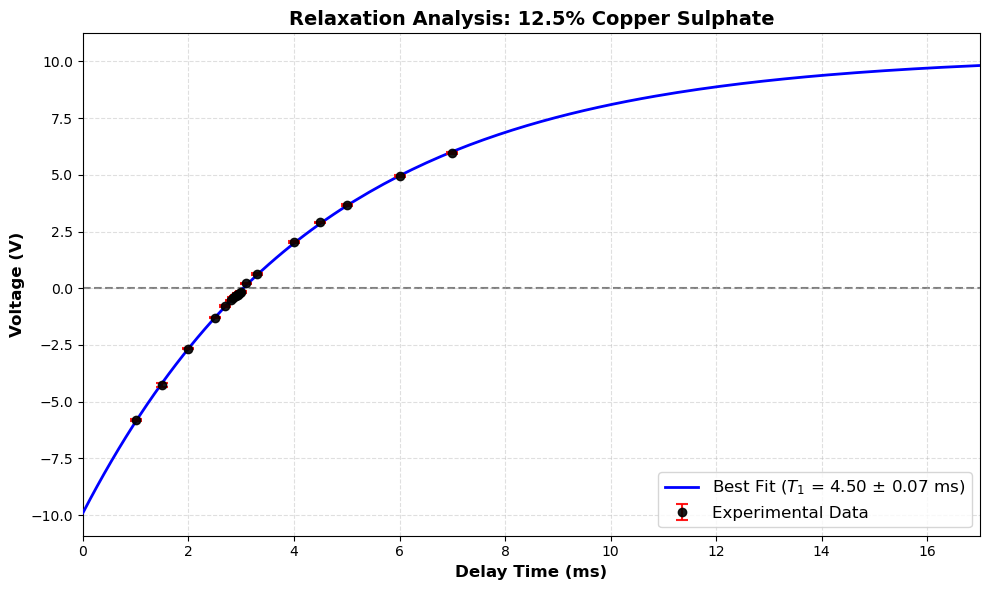

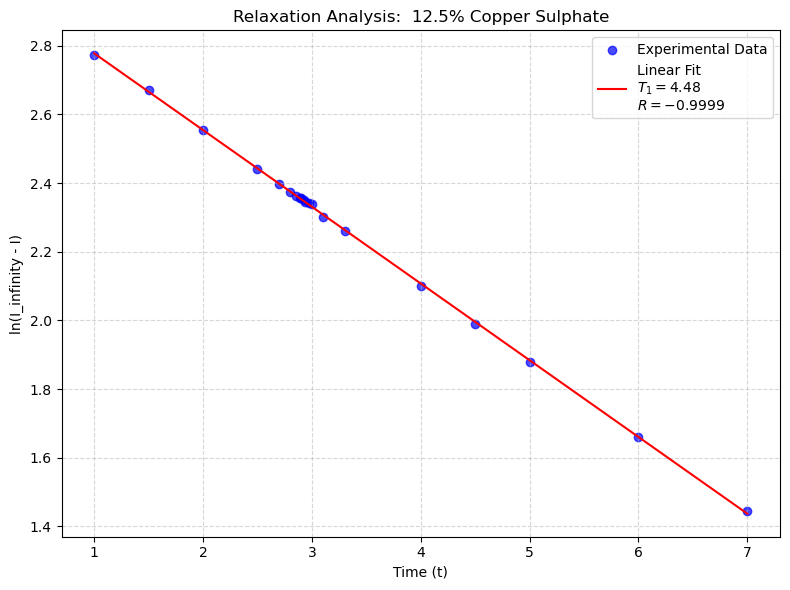

--- Fit Results for Relaxation Analysis: 25% Copper Sulphate ---
Calculated T1: 2.44 ± 0.04 ms
Fitted plateau (a): 7.23 ± 0.08 V
Fitted amplitude (k): 13.35 ± 0.04 V



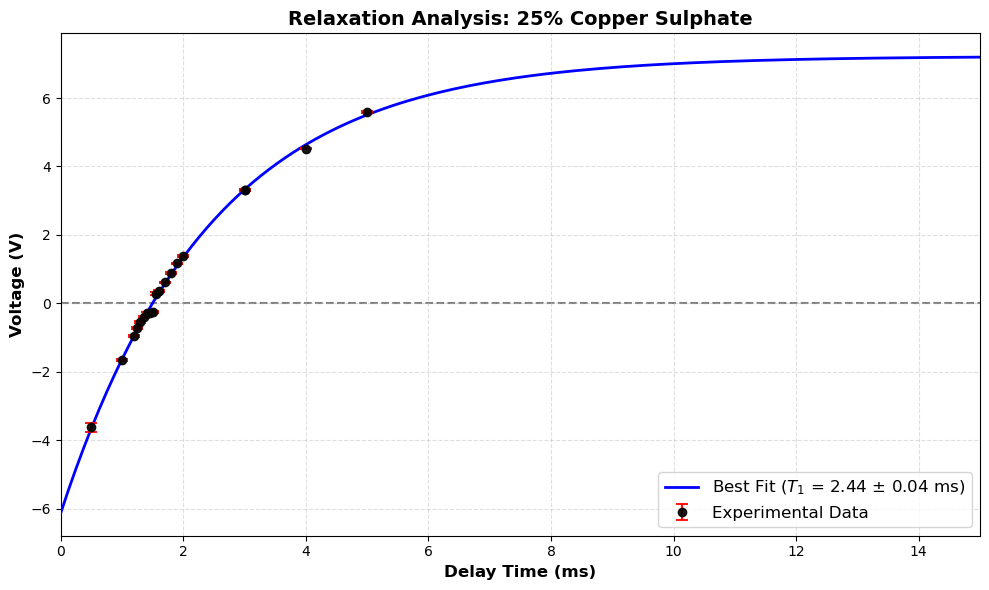

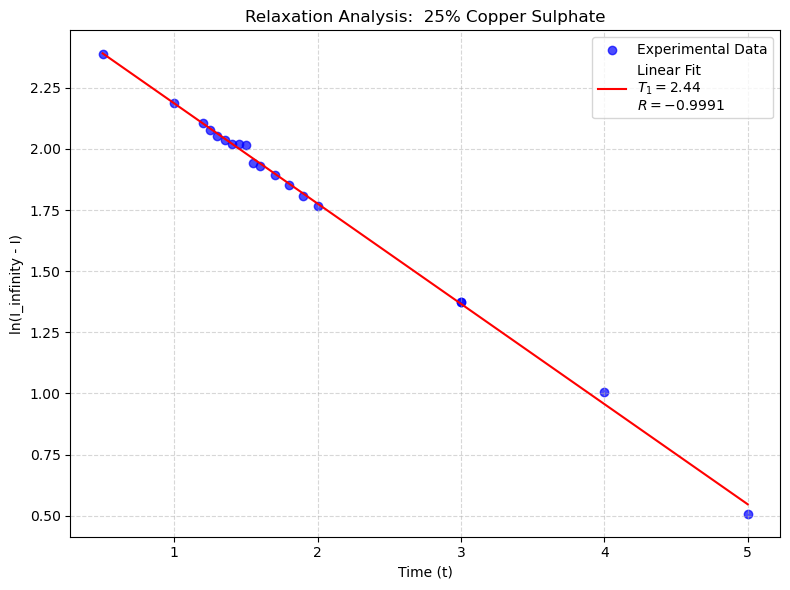

--- Fit Results for Relaxation Analysis: 50% Copper Sulphate ---
Calculated T1: 1.17 ± 0.02 ms
Fitted plateau (a): 6.72 ± 0.09 V
Fitted amplitude (k): 12.17 ± 0.07 V



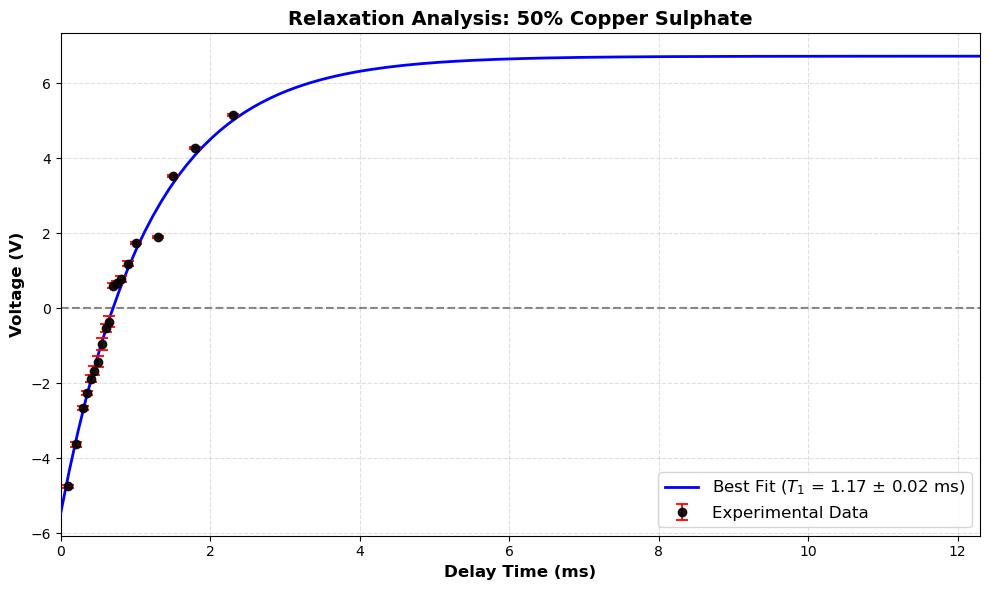

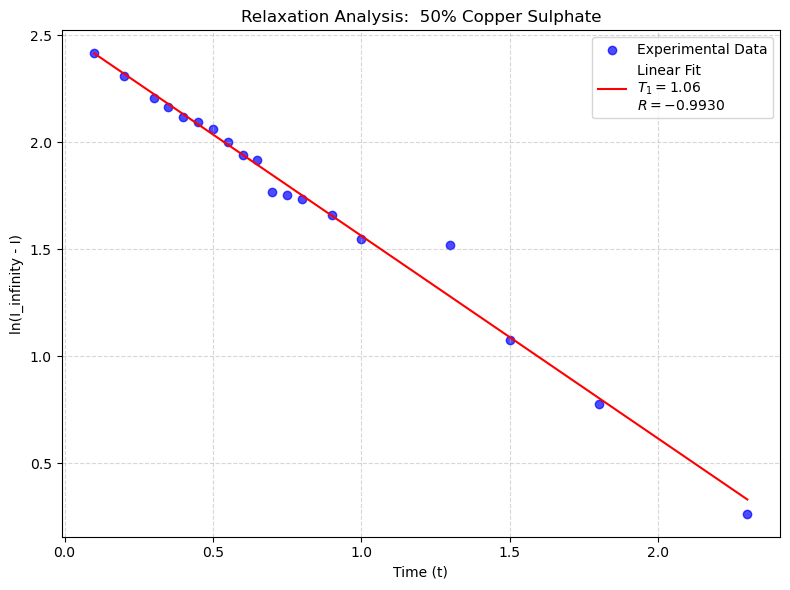

(np.float64(1.0550030712051137), np.float64(-0.9930126711848348))

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress
from scipy.optimize import curve_fit

def analyze_t1(file_path, plot_title):
    """
    Analyzes T1 relaxation data from a CSV file.
    Uses the first 3 columns: Time, Voltage, and Std Dev.
    """
    # 1. Load data
    df = pd.read_csv(file_path)

    # 2. Extract first three columns and clean NaNs
    time = df.iloc[:, 0].values
    voltage = df.iloc[:, 1].values
    mask = ~np.isnan(time) & ~np.isnan(voltage)
    time, voltage = time[mask], voltage[mask]

    # 3. Determine the best Asymptote (I_infinity) for accurate linearization
    def model(t, A, B, T1):
        return A - B * np.exp(-t / T1)
    
    try:
        popt, _ = curve_fit(model, time, voltage, p0=[max(voltage)*1.1, 2*max(voltage), 25])
        I_inf = popt[0]
    except:
        I_inf = max(voltage) * 1.05 # Fallback if fit fails

    # 4. Linearization
    y_lin = np.log(I_inf - voltage)
    x_lin = time

    # 5. Linear Regression to get T1 and R
    res = linregress(x_lin, y_lin)
    t1_calc = -1 / res.slope
    r_val = res.rvalue

    # 6. Create the Plot
    plt.figure(figsize=(8, 6))
    plt.scatter(x_lin, y_lin, color='blue', label='Experimental Data', alpha=0.7)
    
    legend_info = f'Linear Fit\n$T_1 = {t1_calc:.2f}$\n$R = {r_val:.4f}$'
    plt.plot(x_lin, res.slope * x_lin + res.intercept, 'r-', label=legend_info)

    plt.xlabel("Time (t)")
    plt.ylabel("ln(I_infinity - I)")
    plt.title(plot_title)
    plt.legend(loc='best', frameon=True)
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

    return t1_calc, r_val



def process_and_plot(filename, title):
    # 1. Load and Clean Data
    data = pd.read_csv(filename, encoding='windows-1252')
    data = data.iloc[:, 0:3].dropna()

    # Extract columns
    t = data.iloc[:, 0].values        
    V = data.iloc[:, 1].values   

    # Extract 3rd column (Standard Deviation) and convert mV to V
    std_dev = data.iloc[:, 2].values / 1000 
    std_dev = np.where(std_dev == 0, 1e-9, std_dev) # Prevent divide-by-zero errors

    # 2. Define the Mathematical Model
    def recovery_model(t, a, k, T1):
        return a - k * np.exp(-t / T1)

    # 3. Initial Guesses and Bounds
    p0 = [7.0, 14.0, 108.0]
    bounds = ([0, 0, 0], [20, 30, 300])

    # 4. Perform the Curve Fit
    popt, pcov = curve_fit(
        recovery_model, t, V, 
        p0=p0, 
        sigma=std_dev, 
        absolute_sigma=True,
        bounds=bounds
    )

    a_fit, k_fit, T1_fit = popt
    perr = np.sqrt(np.diag(pcov))
    a_err, k_err, T1_err = perr  

    print(f"--- Fit Results for {title} ---")
    print(f"Calculated T1: {T1_fit:.2f} ± {T1_err:.2f} ms")
    print(f"Fitted plateau (a): {a_fit:.2f} ± {a_err:.2f} V")
    print(f"Fitted amplitude (k): {k_fit:.2f} ± {k_err:.2f} V\n")

    # 5. Plotting the Graph
    plt.figure(figsize=(10, 6))

    # Plot raw data with highly visible red error bars
    plt.errorbar(t, V, yerr=std_dev, fmt='o', color='black', 
                 ecolor='red', elinewidth=1.5, capsize=4, capthick=1.5, 
                 label='Experimental Data', alpha=0.9, zorder=5)

    # Generate a smooth curve for the fitted line
    t_smooth = np.linspace(0, max(t) + 20, 200) 

    # Plot the best fit curve AND add the calculated error to the legend
    plt.plot(t_smooth, recovery_model(t_smooth, *popt), color='blue', linewidth=2, 
             label=f'Best Fit ($T_1$ = {T1_fit:.2f} $\pm$ {T1_err:.2f} ms)', zorder=3)

    # Formatting the graph
    plt.axhline(0, color='gray', linestyle='--', zorder=1)
    plt.xlim(0, max(t) + 10) 
    plt.xlabel('Delay Time (ms)', fontsize=12, fontweight='bold')
    plt.ylabel('Voltage (V)', fontsize=12, fontweight='bold')
    plt.title(title, fontsize=14, fontweight='bold')
    plt.legend(fontsize=12, loc='lower right')
    plt.grid(alpha=0.4, linestyle='--')

    # Show the plot instead of saving it 
    plt.tight_layout()
    plt.show()
    # Process 100% Glycerol using the matching file path "C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\copper sulphate\Lowest one 3.1%\T1 1.csv"
process_and_plot(r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\copper sulphate\lowest one 1.5 %\t1.csv", "Relaxation Analysis: 1.5% Copper Sulphate")
analyze_t1(r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\copper sulphate\lowest one 1.5 %\t1.csv", "Relaxation Analysis:  1.5% Copper Sulphate")
process_and_plot(r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\copper sulphate\Lowest one 3.1%\T1 1.csv", "Relaxation Analysis: 3.1% Copper Sulphate")
analyze_t1(r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\copper sulphate\Lowest one 3.1%\T1 1.csv", "Relaxation Analysis:  3.1% Copper Sulphate")



process_and_plot(r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\copper sulphate\6.25%\T1 6.csv", "Relaxation Analysis: 6.25% Copper Sulphate")
analyze_t1(r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\copper sulphate\6.25%\T1 6.csv", "Relaxation Analysis:  6.25% Copper Sulphate")


process_and_plot(r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\copper sulphate\12.5%\T1.csv", "Relaxation Analysis: 12.5% Copper Sulphate")
analyze_t1(r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\copper sulphate\12.5%\T1.csv", "Relaxation Analysis:  12.5% Copper Sulphate")


process_and_plot(r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\copper sulphate\25%\T1.csv", "Relaxation Analysis: 25% Copper Sulphate")
analyze_t1(r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\copper sulphate\25%\T1.csv", "Relaxation Analysis:  25% Copper Sulphate")

process_and_plot(r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\copper sulphate\50%\T1.csv", "Relaxation Analysis: 50% Copper Sulphate")
analyze_t1(r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\copper sulphate\50%\T1.csv", "Relaxation Analysis:  50% Copper Sulphate")


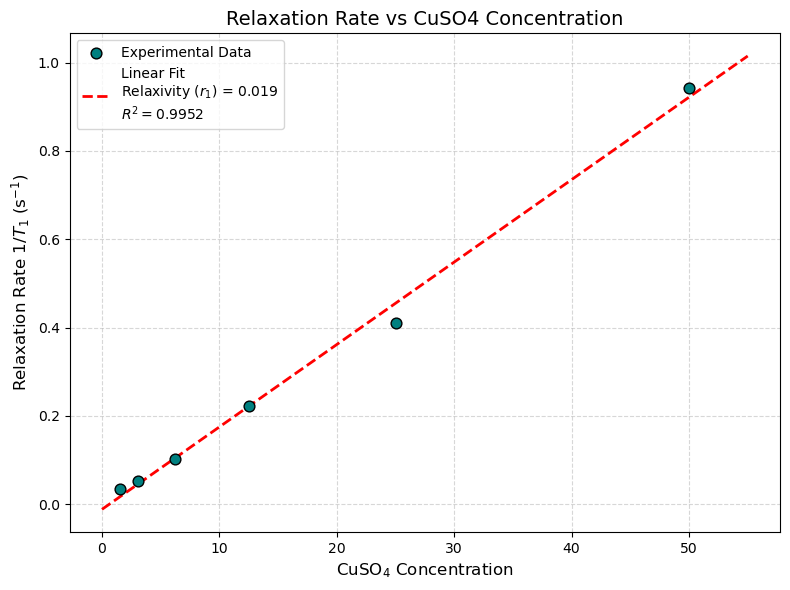

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress

def plot_cuso4_trend(csv_path, graph_title):
    """
    Plots 1/T1 vs Concentration for paramagnetic Copper Sulfate.
    Expects first 3 columns: Concentration, T1, and T1 Error.
    """
    # 1. Load Data
    df = pd.read_csv(csv_path)
    
    # 2. Extract Columns
    conc = df.iloc[:, 0].values
    t1 = df.iloc[:, 1].values
    
    # Clean NaNs
    mask = ~np.isnan(conc) & ~np.isnan(t1)
    conc, t1 = conc[mask], t1[mask]
    
    # 3. Convert T1 to Relaxation Rate (R1 = 1 / T1)
    R1 = 1.0 / t1
    
    # 4. Linear Fit (R1 = r1 * conc + R1_water)
    res = linregress(conc, R1)
    relaxivity = res.slope
    intercept = res.intercept
    r_val = res.rvalue
    
    # 5. Plotting
    plt.figure(figsize=(8, 6))
    
    # Plot experimental data
    plt.scatter(conc, R1, color='teal', label='Experimental Data', s=60, edgecolor='k', zorder=5)
    
    # Plot Fit Line
    conc_fit = np.linspace(0, max(conc)*1.1, 100)
    R1_fit = relaxivity * conc_fit + intercept
    
    fit_label = (f'Linear Fit\n'
                 f'Relaxivity ($r_1$) = {relaxivity:.3f}\n'
                 f'$R^2 = {r_val**2:.4f}$')
                 
    plt.plot(conc_fit, R1_fit, 'r--', linewidth=2, label=fit_label)

    plt.xlabel('CuSO$_4$ Concentration', fontsize=12)
    plt.ylabel('Relaxation Rate $1/T_1$ (s$^{-1}$)', fontsize=12)
    plt.title(graph_title, fontsize=14)
    plt.legend(loc='best', frameon=True)
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

# --- CALL THE FUNCTION ---
# plot_cuso4_trend(r"C:\Path\To\Your\cuso4_master.csv", "Relaxation Rate vs CuSO4 Concentration")

plot_cuso4_trend(r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\copper sulphate\master.csv", "Relaxation Rate vs CuSO4 Concentration")

# --- TO RUN THE CODE ---
# Ensure the line below has NO SPACES at the start
# analyze_cuso4_relaxivity(r"C:\Users\...\your_file.csv", "Relaxivity of Copper Sulfate")

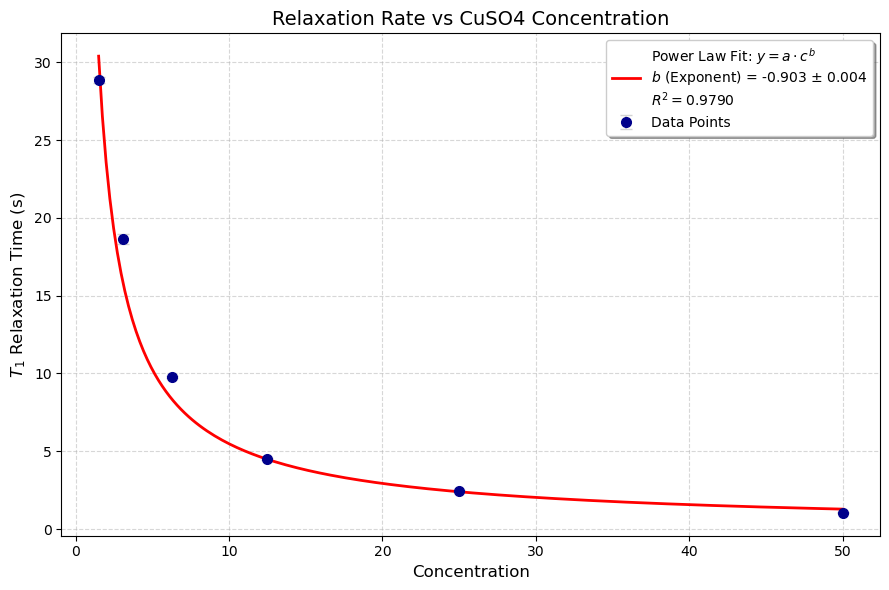

Power Law Result: T1 = 43.827 * Concentration^(-0.903)


In [15]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

def plot_t1_power_law(file_path, plot_title):
    """
    Plots T1 vs Concentration and fits a Power Law (y = a * x^b).
    Expects first 3 columns: Concentration, T1, and T1 Error.
    """
    # 1. Load the data
    df = pd.read_csv(file_path)
    
    # 2. Extract first 3 columns
    x_data = df.iloc[:, 0].values # Concentration
    y_data = df.iloc[:, 1].values # T1
    y_err  = df.iloc[:, 2].values # T1 Error
    
    # 3. Clean and Sort
    mask = ~np.isnan(x_data) & ~np.isnan(y_data) & (x_data > 0) # Powers need x > 0
    x, y, err = x_data[mask], y_data[mask], y_err[mask]
    
    idx = np.argsort(x)
    x, y, err = x[idx], y[idx], err[idx]

    # 4. Define Power Law Model: y = a * x^b
    def power_model(c, a, b):
        return a * np.power(c, b)

    # 5. Fit the Curve
    # Initial guess: b = -1, a = mean(y * x)
    p0 = [np.mean(y * x), -1.0]
    
    try:
        popt, pcov = curve_fit(power_model, x, y, p0=p0, sigma=err, absolute_sigma=True)
        a_fit, b_fit = popt
        perr = np.sqrt(np.diag(pcov)) # Standard errors for parameters
        
        # Generate smooth curve
        x_smooth = np.linspace(x.min(), x.max(), 200)
        y_smooth = power_model(x_smooth, a_fit, b_fit)
        
        # Calculate R-squared
        residuals = y - power_model(x, *popt)
        r_sq = 1 - (np.sum(residuals**2) / np.sum((y - np.mean(y))**2))
        
        label_text = (f'Power Law Fit: $y = a \cdot c^b$\n'
                      f'$b$ (Exponent) = {b_fit:.3f} $\pm$ {perr[1]:.3f}\n'
                      f'$R^2 = {r_sq:.4f}$')
    except Exception as e:
        print(f"Fit failed: {e}")
        x_smooth, y_smooth, label_text = None, None, "Fit Failed"

    # 6. Plotting
    plt.figure(figsize=(9, 6))
    plt.errorbar(x, y, yerr=err, fmt='o', color='darkblue', 
                 ecolor='lightgray', capsize=4, label='Data Points', markersize=7)
    
    if x_smooth is not None:
        plt.plot(x_smooth, y_smooth, 'r-', linewidth=2, label=label_text)

    plt.xlabel('Concentration', fontsize=12)
    plt.ylabel('$T_1$ Relaxation Time (s)', fontsize=12)
    plt.title(plot_title, fontsize=14)
    plt.legend(loc='best', frameon=True, shadow=True)
    plt.grid(True, linestyle='--', alpha=0.5)
    
    plt.tight_layout()
    plt.show()
    
    if x_smooth is not None:
        print(f"Power Law Result: T1 = {a_fit:.3f} * Concentration^({b_fit:.3f})")

plot_t1_power_law(r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\copper sulphate\master.csv", "Relaxation Rate vs CuSO4 Concentration")
